<small>Dataset: Student_Performance.csv</small>

# Q11. Student Performance Regression

Predict the numeric Performance Index from the supplied student attributes.


## Question from Classroom

Student Performance Prediction Using Regression 
Problem statement: Predict students' final examination scores using academic and 
behavioral attributes. 
Dataset: student performance — Kaggle 
Tasks to be performed: 
1. Load a student performance dataset. 
2. Examine relationships between study hours, attendance, previous marks and final 
scores. 
3. Select suitable input features and the numerical target variable. 
4. Train a Linear Regression model using a train-test split. 
5. Predict scores for unseen student records. 
6. Evaluate using R², RMSE and MAE. 
7. Identify the features associated with higher or lower predicted performance.


## Understand before coding

Select inputs -> split -> impute training medians -> train linear regression -> compare predictions and explain coefficients.


**Dataset / practice note:** The supplied file has no attendance/final-exam columns. This notebook uses its actual Performance Index and available predictors.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a student performance dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

df=pd.read_csv("data/Student_Performance.csv").dropna(subset=["Performance Index"])
df["Extracurricular Activities"]=df["Extracurricular Activities"].map({"Yes":1,"No":0})


## Task 2. Examine relationships between study hours, attendance, previous marks and final scores.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (10000, 6)
   Hours Studied  ...  Performance Index
0              7  ...               91.0
1              4  ...               65.0
2              8  ...               45.0
3              5  ...               36.0
4              7  ...               66.0

[5 rows x 6 columns]
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  int64  
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 468.9 KB
Missing values:
 Hours Studied                       0
Previou

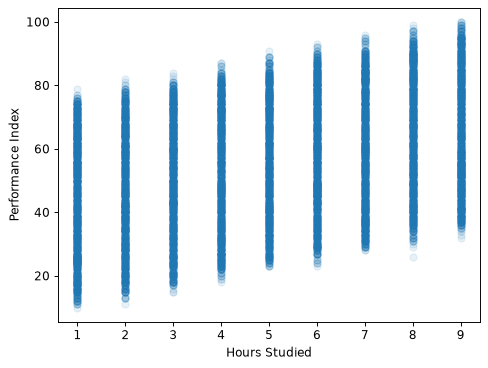

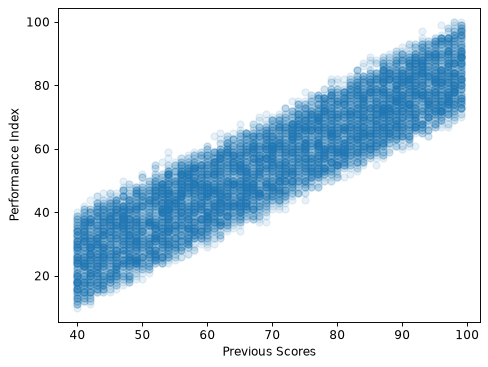

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)

print("Actual columns:",df.columns.tolist())
print("Attendance is not in this file; use available student attributes.")
for column in ["Hours Studied","Previous Scores"]:
    plt.scatter(df[column],df["Performance Index"],alpha=0.1)
    plt.xlabel(column);plt.ylabel("Performance Index");plt.show()


## Task 3. Select suitable input features and the numerical target variable.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X=df.drop(columns="Performance Index")
y=df["Performance Index"]
print("Features:",X.columns.tolist(),"Target: Performance Index")


Features: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced'] Target: Performance Index


## Task 4. Train a Linear Regression model using a train-test split.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
medians=X_train.median()
X_train=X_train.fillna(medians)
X_test=X_test.fillna(medians)

model=LinearRegression()
model.fit(X_train,y_train)


## Task 5. Predict scores for unseen student records.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
prediction=model.predict(X_test)
print("Predictions for unseen records:",prediction[:5])


Predictions for unseen records: [54.71185392 22.61551294 47.90314471 31.28976748 43.00457042]


## Task 6. Evaluate using R², RMSE and MAE.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
print("R2:",round(r2_score(y_test,prediction),4))
print("RMSE:",round(np.sqrt(mean_squared_error(y_test,prediction)),2))
print("MAE:",round(mean_absolute_error(y_test,prediction),2))
print(pd.DataFrame({"Actual":np.asarray(y_test),"Predicted":prediction}).head(10))


R2: 0.989
RMSE: 2.02
MAE: 1.61
   Actual  Predicted
0    51.0  54.711854
1    20.0  22.615513
2    46.0  47.903145
3    28.0  31.289767
4    41.0  43.004570
5    59.0  59.071252
6    48.0  45.903475
7    87.0  86.459118
8    37.0  37.700140
9    73.0  72.055925


## Task 7. Identify the features associated with higher or lower predicted performance.

This block implements the task above. Variables from earlier blocks are reused.


In [7]:
print("Intercept:",model.intercept_)
print("Feature coefficients (associations, not causal effects):")
print(pd.Series(model.coef_,index=X.columns).sort_values())


Intercept: -33.921946215556126
Feature coefficients (associations, not causal effects):
Sample Question Papers Practiced    0.191831
Sleep Hours                         0.476941
Extracurricular Activities          0.608617
Previous Scores                     1.016988
Hours Studied                       2.852484
dtype: float64


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What is linear regression?**

It fits y_hat = b0 + b1*x1 + ... + bp*xp, normally by minimizing the sum of squared training residuals.

**10. What are intercept and coefficients?**

The intercept is the predicted value when encoded inputs are zero. A coefficient describes the change in prediction per unit of that feature, holding the others fixed; association does not prove causation.

**11. Define MAE and RMSE.**

MAE=mean(abs(y-y_hat)). RMSE=sqrt(mean((y-y_hat)^2)). Both use the target units; lower is better. RMSE penalizes large errors more strongly.

**12. What is R2?**

R2=1-SSE/SST. A perfect prediction scores 1. A negative score means worse squared error than predicting the test target mean. It is not accuracy or a percentage of correct records.

**13. How do I interpret actual vs predicted?**

Points near the diagonal indicate small errors. Systematic curves or large scatter suggest model limitations. Do not invent a good score when the dataset has weak signal.

**14. Which columns does this actual dataset contain?**

Hours Studied, Previous Scores, Extracurricular Activities, Sleep Hours, Sample Question Papers Practiced and Performance Index. There is no attendance column.

**15. What is the target?**

Performance Index, a numerical score. It must be excluded from the predictor table.

**16. How is a positive coefficient interpreted?**

Increasing that feature by one unit raises the predicted score by the coefficient, with other encoded features fixed. This is an association, not proof of causation.

**17. Can the model predict an impossible score?**

An unconstrained linear model can predict outside a score range, especially for unusual inputs. Check the data range and report this limitation rather than silently changing predictions.

**18. How do I predict a new student?**

Create one row with exactly the same feature names and encodings as X_train, apply the same missing-value treatment, and call model.predict().


### Task-to-code map

- **Block 1:** Load a student performance dataset.
- **Block 2:** Examine relationships between study hours, attendance, previous marks and final scores.
- **Block 3:** Select suitable input features and the numerical target variable.
- **Block 4:** Train a Linear Regression model using a train-test split.
- **Block 5:** Predict scores for unseen student records.
- **Block 6:** Evaluate using R², RMSE and MAE.
- **Block 7:** Identify the features associated with higher or lower predicted performance.
